In [2]:
import xarray as xr
import numpy as np
from pathlib import Path

PROJECT_PATH = Path.cwd().parent


NC_PATH = PROJECT_PATH / "Raw_Data" / "MODIS_NVDI" / "MOD13Q1.061_250m_aid0001.nc"

if not NC_PATH.exists():
    raise FileNotFoundError(f"File not found: {NC_PATH}")


ds = xr.open_dataset(NC_PATH)

print("File opened successfully!")
print("File size:", round(NC_PATH.stat().st_size / (1024**2), 2), "MB")


File opened successfully!
File size: 3.79 MB


In [3]:
print("Dimensions:")
print(ds.sizes)

print("\nVariables:")
print(list(ds.data_vars))

print("\nCoordinates:")
print(list(ds.coords))

print("\nDataset Information:")
print(ds)


Dimensions:
Frozen({'time': 249, 'ydim': 97, 'xdim': 110})

Variables:
['crs', '_250m_16_days_NDVI', '_250m_16_days_VI_Quality', '_250m_16_days_pixel_reliability']

Coordinates:
['time', 'ydim', 'xdim']

Dataset Information:
<xarray.Dataset> Size: 64MB
Dimensions:                          (time: 249, ydim: 97, xdim: 110)
Coordinates:
  * time                             (time) object 2kB 2014-12-19 00:00:00 .....
  * ydim                             (ydim) float64 776B 3.407e+06 ... 3.385e+06
  * xdim                             (xdim) float64 880B 2.999e+06 ... 3.025e+06
Data variables:
    crs                              int8 1B ...
    _250m_16_days_NDVI               (time, ydim, xdim) float64 21MB ...
    _250m_16_days_VI_Quality         (time, ydim, xdim) float64 21MB ...
    _250m_16_days_pixel_reliability  (time, ydim, xdim) float64 21MB ...
Attributes:
    title:        MOD13Q1.061 for aid0001
    Conventions:  CF-1.6
    institution:  Land Processes Distributed Active Archiv

In [4]:

for variable in ds.data_vars:
    print("\n" + "=" * 50)
    print("Variable:", variable)

    data = ds[variable]

    print("Dimensions:", data.dims)
    print("Shape:", data.shape)
    print("Data Type:", data.dtype)

    print("\nAttributes:")
    for key, value in data.attrs.items():
        print(f"{key}: {value}")



Variable: crs
Dimensions: ()
Shape: ()
Data Type: int8

Attributes:
grid_mapping_name: sinusoidal
_CoordinateAxisTypes: GeoX GeoY
spatial_ref: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
radius_of_sphere: 6371007.181
longitude_of_central_meridian: 0
longitude_of_projection_origin: 0
straight_vertical_longitude_from_pole: 0
false_easting: 0
false_northing: 0

Variable: _250m_16_days_NDVI
Dimensions: ('time', 'ydim', 'xdim')
Shape: (249, 97, 110)
Data Type: float64

Attributes:
grid_mapping: crs
valid_min: -2000
valid_max: 10000
add_offset_err: 0.0
calibrated_nt: 5
long_name: 250m 16 days NDVI
scale_factor_err: 0.0
units: NDVI
AREA_OR_POINT

In [5]:
ndvi = ds["_250m_16_days_NDVI"]
reliability = ds["_250m_16_days_pixel_reliability"]
vi_quality = ds["_250m_16_days_VI_Quality"]

# 1. NDVI inspection
print("=" * 50)
print("NDVI INSPECTION")

print("Attributes:", ndvi.attrs)
print("Encoding:", ndvi.encoding)

valid_ndvi = ndvi.where(np.isfinite(ndvi))

print("\nStatistics:")
print("Minimum:", float(valid_ndvi.min().values))
print("Maximum:", float(valid_ndvi.max().values))
print("Mean:", float(valid_ndvi.mean().values))
print("Missing values:", int(ndvi.isnull().sum().values))
print("Total values:", ndvi.size)

# 2. Pixel Reliability inspection
print("\n" + "=" * 50)
print("PIXEL RELIABILITY")

print("Attributes:", reliability.attrs)

values, counts = np.unique(
    reliability.values,
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels")

# 3. VI Quality inspection
print("\n" + "=" * 50)
print("VI QUALITY")

print("Attributes:", vi_quality.attrs)
print("Data Type:", vi_quality.dtype)

values, counts = np.unique(
    vi_quality.values,
    return_counts=True
)

print("\nFirst 20 unique values:")
for value, count in zip(values[:20], counts[:20]):
    print(f"Value {value}: {count:,} pixels")

print("\nTotal unique values:", len(values))

# 4. Time inspection
print("\n" + "=" * 50)
print("TIME INSPECTION")

print("First date:", ds.time.values[0])
print("Last date:", ds.time.values[-1])
print("Number of dates:", len(ds.time))


NDVI INSPECTION
Attributes: {'grid_mapping': 'crs', 'valid_min': np.int16(-2000), 'valid_max': np.int16(10000), 'add_offset_err': np.float64(0.0), 'calibrated_nt': np.int64(5), 'long_name': '250m 16 days NDVI', 'scale_factor_err': np.float64(0.0), 'units': 'NDVI', 'AREA_OR_POINT': 'Area', 'res': array([231.65635826, 231.65635826]), 'is_tiled': np.uint8(1), 'nodatavals': np.float64(-3000.0)}
Encoding: {'dtype': dtype('int16'), 'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': True, 'complevel': 4, 'fletcher32': False, 'contiguous': False, 'chunksizes': (125, 49, 55), 'preferred_chunks': {'time': 125, 'ydim': 49, 'xdim': 55}, 'source': 'g:\\FarmWise\\Raw_Data\\MODIS_NVDI\\MOD13Q1.061_250m_aid0001.nc', 'original_shape': (249, 97, 110), '_FillValue': np.int16(-3000), 'scale_factor': np.float64(0.0001), 'add_offset': np.float64(0.0), 'coordinates': 'time ydim xdim'}

Statistics:
Minimum: 0.066
Maximum: 0.9959
Mean: 0.5308355680580871
Missing values: 6289

In [6]:
# Check missing values across all time steps

missing_mask = ndvi.isnull()

# Pixels that are missing in every time step
always_missing = missing_mask.all(dim="time")

# Pixels that are missing in at least one time step
ever_missing = missing_mask.any(dim="time")

# Pixels that are never missing
never_missing = (~missing_mask).all(dim="time")

print("SPATIAL MISSING DATA ANALYSIS")
print("-" * 40)

print("Total spatial pixels:", ndvi.sizes["ydim"] * ndvi.sizes["xdim"])

print("Always missing pixels:",
      int(always_missing.sum().values))

print("Ever missing pixels:",
      int(ever_missing.sum().values))

print("Never missing pixels:",
      int(never_missing.sum().values))

print("\nMissing values per time step:")
missing_per_date = missing_mask.sum(dim=["ydim", "xdim"])

print("Minimum:", int(missing_per_date.min().values))
print("Maximum:", int(missing_per_date.max().values))
print("Mean:", float(missing_per_date.mean().values))


SPATIAL MISSING DATA ANALYSIS
----------------------------------------
Total spatial pixels: 10670
Always missing pixels: 2526
Ever missing pixels: 2526
Never missing pixels: 8144

Missing values per time step:
Minimum: 2526
Maximum: 2526
Mean: 2526.0


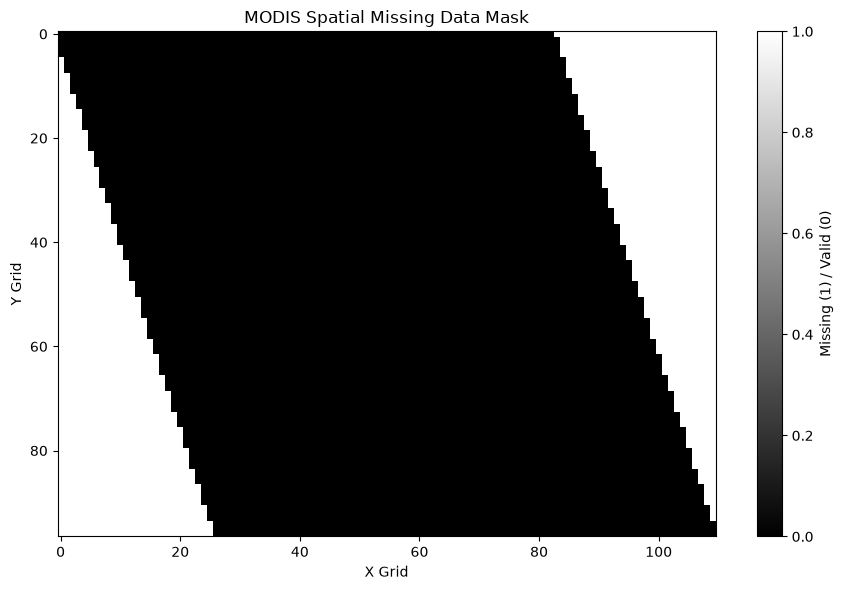

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.imshow(
    always_missing.values,
    cmap="gray",
    interpolation="nearest",
    aspect="auto"
)

plt.title("MODIS Spatial Missing Data Mask")
plt.xlabel("X Grid")
plt.ylabel("Y Grid")
plt.colorbar(label="Missing (1) / Valid (0)")

plt.tight_layout()
plt.show()


In [9]:

# Inspect the first dates in the dataset

print("First 10 MODIS dates:")

for date in ds.time.values[:10]:
    print(date)

print("\nDates around January 2015:")

for date in ds.time.values:
    if date.year == 2015 and date.month <= 2:
        print(date)


First 10 MODIS dates:
2014-12-19 00:00:00
2015-01-01 00:00:00
2015-01-17 00:00:00
2015-02-02 00:00:00
2015-02-18 00:00:00
2015-03-06 00:00:00
2015-03-22 00:00:00
2015-04-07 00:00:00
2015-04-23 00:00:00
2015-05-09 00:00:00

Dates around January 2015:
2015-01-01 00:00:00
2015-01-17 00:00:00
2015-02-02 00:00:00
2015-02-18 00:00:00


In [10]:
import pandas as pd
from pathlib import Path

# 1. Find the FarmWise project folder
current = Path.cwd()
PROJECT_PATH = None

for folder in [current, *current.parents]:
    if (folder / "Raw_Data").exists() or (folder / "01_Raw_Data").exists():
        PROJECT_PATH = folder
        break

if PROJECT_PATH is None:
    raise FileNotFoundError("Could not find the FarmWise project folder.")

# 2. Create output folder
OUTPUT_PATH = PROJECT_PATH / "Processed_Data" / "MODIS_NDVI"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# 3. Keep observations from 2015 onwards
time_indices = [
    i for i, date in enumerate(ds.time.values)
    if date.year >= 2015
]

ds_2015 = ds.isel(time=time_indices)

# 4. Select required variables
data = ds_2015[
    [
        "_250m_16_days_NDVI",
        "_250m_16_days_pixel_reliability",
        "_250m_16_days_VI_Quality"
    ]
].rename({
    "_250m_16_days_NDVI": "NDVI",
    "_250m_16_days_pixel_reliability": "Reliability",
    "_250m_16_days_VI_Quality": "VI_Quality"
})

# 5. Convert to a detailed DataFrame
detailed_df = data.to_dataframe().reset_index()

# 6. Keep pixels with valid NDVI
detailed_df = detailed_df.dropna(subset=["NDVI"]).copy()

# Rename spatial coordinates
detailed_df = detailed_df.rename(columns={
    "xdim": "X_sinusoidal_m",
    "ydim": "Y_sinusoidal_m"
})

# 7. Save detailed CSV
detailed_file = OUTPUT_PATH / "MODIS_NDVI_Detailed.csv"

detailed_df.to_csv(
    detailed_file,
    index=False
)

# 8. Calculate summary statistics using Good pixels only
ndvi = ds_2015["_250m_16_days_NDVI"]
reliability = ds_2015["_250m_16_days_pixel_reliability"]

good_ndvi = ndvi.where(reliability == 0)

marginal_included_ndvi = ndvi.where(
    (reliability == 0) | (reliability == 1)
)

summary = pd.DataFrame({
    "Date": ds_2015.time.values,
    "Mean_NDVI_Good": good_ndvi.mean(
        dim=["ydim", "xdim"], skipna=True
    ).values,
    "Good_Pixel_Count": good_ndvi.count(
        dim=["ydim", "xdim"]
    ).values,
    "Mean_NDVI_Good_Marginal": marginal_included_ndvi.mean(
        dim=["ydim", "xdim"], skipna=True
    ).values,
    "Good_Marginal_Pixel_Count": marginal_included_ndvi.count(
        dim=["ydim", "xdim"]
    ).values
})

# 9. Save summary CSV
summary_file = OUTPUT_PATH / "MODIS_NDVI_Summary.csv"
summary.to_csv(summary_file, index=False)

# 10. Report
print("EXPORT COMPLETED!")
print("-" * 40)

print("Detailed rows:", len(detailed_df))
print("Summary rows:", len(summary))

print("\nDetailed file:", detailed_file)
print("Summary file:", summary_file)

print("\nDetailed preview:")
print(detailed_df.head())

print("\nSummary preview:")
print(summary.head())


EXPORT COMPLETED!
----------------------------------------
Detailed rows: 2019712
Summary rows: 248

Detailed file: g:\FarmWise\Processed_Data\MODIS_NDVI\MODIS_NDVI_Detailed.csv
Summary file: g:\FarmWise\Processed_Data\MODIS_NDVI\MODIS_NDVI_Summary.csv

Detailed preview:
                  time  Y_sinusoidal_m  X_sinusoidal_m    NDVI  Reliability  \
0  2015-01-01 00:00:00    3.407086e+06    2.999371e+06  0.8185          0.0   
1  2015-01-01 00:00:00    3.407086e+06    2.999602e+06  0.7962          0.0   
2  2015-01-01 00:00:00    3.407086e+06    2.999834e+06  0.8065          0.0   
3  2015-01-01 00:00:00    3.407086e+06    3.000066e+06  0.8190          0.0   
4  2015-01-01 00:00:00    3.407086e+06    3.000297e+06  0.7683          0.0   

   VI_Quality  
0      2116.0  
1      2116.0  
2      2116.0  
3      2116.0  
4      2116.0  

Summary preview:
                  Date  Mean_NDVI_Good  Good_Pixel_Count  \
0  2015-01-01 00:00:00        0.688029              8128   
1  2015-01-17 00:00

In [11]:

# Read exported CSV files
detailed_check = pd.read_csv(detailed_file)
summary_check = pd.read_csv(summary_file)

print("FINAL VALIDATION")
print("=" * 45)

# Detailed dataset checks
print("\nDETAILED DATASET")
print("Rows:", len(detailed_check))
print("Unique dates:", detailed_check["time"].nunique())
print("Date range:",
      detailed_check["time"].min(),
      "to",
      detailed_check["time"].max())

print("Missing NDVI:", detailed_check["NDVI"].isna().sum())
print("Missing Reliability:",
      detailed_check["Reliability"].isna().sum())

print("\nReliability distribution:")
print(detailed_check["Reliability"].value_counts().sort_index())

# Summary dataset checks
print("\nSUMMARY DATASET")
print("Rows:", len(summary_check))
print("Missing values:")
print(summary_check.isna().sum())

print("\nNDVI Mean range:")
print(summary_check["Mean_NDVI_Good"].min())
print(summary_check["Mean_NDVI_Good"].max())

# Check expected number of records
expected_rows = 8144 * 248

print("\nEXPECTED ROWS:", expected_rows)
print("ACTUAL ROWS:", len(detailed_check))
print("Row count matches:", len(detailed_check) == expected_rows)


FINAL VALIDATION

DETAILED DATASET
Rows: 2019712
Unique dates: 248
Date range: 2015-01-01 00:00:00 to 2025-09-30 00:00:00
Missing NDVI: 0
Missing Reliability: 0

Reliability distribution:
Reliability
0.0    1884395
1.0     121567
3.0      13750
Name: count, dtype: int64

SUMMARY DATASET
Rows: 248
Missing values:
Date                         0
Mean_NDVI_Good               0
Good_Pixel_Count             0
Mean_NDVI_Good_Marginal      0
Good_Marginal_Pixel_Count    0
dtype: int64

NDVI Mean range:
0.2933835908568509
0.7339971368531654

EXPECTED ROWS: 2019712
ACTUAL ROWS: 2019712
Row count matches: True


In [12]:
print(ds)

<xarray.Dataset> Size: 64MB
Dimensions:                          (time: 249, ydim: 97, xdim: 110)
Coordinates:
  * time                             (time) object 2kB 2014-12-19 00:00:00 .....
  * ydim                             (ydim) float64 776B 3.407e+06 ... 3.385e+06
  * xdim                             (xdim) float64 880B 2.999e+06 ... 3.025e+06
Data variables:
    crs                              int8 1B ...
    _250m_16_days_NDVI               (time, ydim, xdim) float64 21MB 0.8288 ....
    _250m_16_days_VI_Quality         (time, ydim, xdim) float64 21MB 2.185e+0...
    _250m_16_days_pixel_reliability  (time, ydim, xdim) float64 21MB 1.0 ... 0.0
Attributes:
    title:        MOD13Q1.061 for aid0001
    Conventions:  CF-1.6
    institution:  Land Processes Distributed Active Archive Center (LP DAAC)
    source:       AppEEARS v3.137
    references:   See README.md
    history:      See README.md


In [13]:
print(ds["crs"].attrs)

{'grid_mapping_name': 'sinusoidal', '_CoordinateAxisTypes': 'GeoX GeoY', 'spatial_ref': 'PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]', 'radius_of_sphere': np.float64(6371007.181), 'longitude_of_central_meridian': np.int64(0), 'longitude_of_projection_origin': np.int64(0), 'straight_vertical_longitude_from_pole': np.int64(0), 'false_easting': np.int64(0), 'false_northing': np.int64(0)}


In [14]:
print(ds.attrs)
print(ds["_250m_16_days_NDVI"].attrs)

{'title': 'MOD13Q1.061 for aid0001', 'Conventions': 'CF-1.6', 'institution': 'Land Processes Distributed Active Archive Center (LP DAAC)', 'source': 'AppEEARS v3.137', 'references': 'See README.md', 'history': 'See README.md'}
{'grid_mapping': 'crs', 'valid_min': np.int16(-2000), 'valid_max': np.int16(10000), 'add_offset_err': np.float64(0.0), 'calibrated_nt': np.int64(5), 'long_name': '250m 16 days NDVI', 'scale_factor_err': np.float64(0.0), 'units': 'NDVI', 'AREA_OR_POINT': 'Area', 'res': array([231.65635826, 231.65635826]), 'is_tiled': np.uint8(1), 'nodatavals': np.float64(-3000.0)}


In [15]:
from pyproj import CRS, Transformer

# Define the MODIS Sinusoidal CRS
modis_crs = CRS.from_proj4(
    "+proj=sinu +R=6371007.181 +lon_0=0 "
    "+x_0=0 +y_0=0 +units=m +no_defs"
)

# Convert to Geographic Coordinates (WGS84)
wgs84 = CRS.from_epsg(4326)

transformer = Transformer.from_crs(
    modis_crs,
    wgs84,
    always_xy=True
)

# Get pixel coordinates
x = ds["xdim"].values
y = ds["ydim"].values

# Test one pixel
lon, lat = transformer.transform(x[len(x)//2], y[len(y)//2])

print("Longitude:", lon)
print("Latitude:", lat)

Longitude: 31.45189154879601
Latitude: 30.54062499707425


In [16]:
import numpy as np
import pandas as pd

# Create all pixel coordinates
X, Y = np.meshgrid(
    ds["xdim"].values,
    ds["ydim"].values
)

# Convert all pixels to Longitude and Latitude
lon, lat = transformer.transform(X, Y)

# Create a DataFrame
coordinates = pd.DataFrame({
    "Longitude": lon.flatten(),
    "Latitude": lat.flatten()
})

print(coordinates.describe())
print("\nFirst 5 pixels:")
print(coordinates.head())

          Longitude      Latitude
count  10670.000000  10670.000000
mean      31.450710     30.540625
std        0.079101      0.058336
min       31.286682     30.440625
25%       31.384170     30.490625
50%       31.450688     30.540625
75%       31.517200     30.590625
max       31.615116     30.640625

First 5 pixels:
   Longitude   Latitude
0  31.351183  30.640625
1  31.353604  30.640625
2  31.356026  30.640625
3  31.358447  30.640625
4  31.360869  30.640625


In [17]:
print("Grid dimensions:", ds.sizes)

print("Longitude range:",
      lon.min(), lon.max())

print("Latitude range:",
      lat.min(), lat.max())

Grid dimensions: Frozen({'time': 249, 'ydim': 97, 'xdim': 110})
Longitude range: 31.28668180026518 31.615116394860188
Latitude range: 30.440624997083837 30.640624997064677


In [19]:
import json

aoi_path = r"G:/FarmWise/Documentation/AOI/El_Zankalon_AOI.geojson"

with open(aoi_path, "r") as file:
    aoi = json.load(file)

print(aoi["type"])
print(aoi["features"][0]["geometry"]["type"])
print(aoi["features"][0]["geometry"]["coordinates"])

FeatureCollection
Polygon
[[[31.35, 30.44], [31.55, 30.44], [31.55, 30.64], [31.35, 30.64], [31.35, 30.44]]]


In [20]:
# Check which pixel centers are inside the AOI

inside_aoi = (
    (lon >= 31.35) &
    (lon <= 31.55) &
    (lat >= 30.44) &
    (lat <= 30.64)
)

# Count pixels
total_pixels = inside_aoi.size
inside_pixels = inside_aoi.sum()
outside_pixels = total_pixels - inside_pixels

print("Total Grid Pixels:", total_pixels)
print("Pixels Inside AOI:", inside_pixels)
print("Pixels Outside AOI:", outside_pixels)

print("Inside AOI Percentage:",
      round(inside_pixels / total_pixels * 100, 2), "%")

Total Grid Pixels: 10670
Pixels Inside AOI: 7937
Pixels Outside AOI: 2733
Inside AOI Percentage: 74.39 %


In [21]:
import xarray as xr
import numpy as np

# Create spatial mask
inside_mask = xr.DataArray(
    inside_aoi,
    dims=("ydim", "xdim"),
    coords={
        "ydim": ds.ydim,
        "xdim": ds.xdim
    }
)

# Select dates from 2015 onward
time_years = np.array([t.year for t in ds.time.values])
ds_2015 = ds.isel(time=np.where(time_years >= 2015)[0])

# Apply AOI mask
ndvi_aoi = ds_2015["_250m_16_days_NDVI"].where(inside_mask)

reliability_aoi = ds_2015[
    "_250m_16_days_pixel_reliability"
].where(inside_mask)

# Count valid observations
print("Pixels inside AOI:", int(inside_mask.sum()))

print("Valid NDVI observations:",
      int(ndvi_aoi.count()))

print("\nReliability distribution inside AOI:")
print(reliability_aoi.to_series().value_counts(dropna=True).sort_index())

Pixels inside AOI: 7937
Valid NDVI observations: 1968376

Reliability distribution inside AOI:
_250m_16_days_pixel_reliability
0.0    1836503
1.0     118367
3.0      13506
Name: count, dtype: int64


In [22]:
vi_quality_aoi = ds_2015[
    "_250m_16_days_VI_Quality"
].where(inside_mask)

print(vi_quality_aoi)
print("\nUnique VI Quality values:")
print(np.unique(vi_quality_aoi.values[~np.isnan(vi_quality_aoi.values)])[:30])

<xarray.DataArray '_250m_16_days_VI_Quality' (time: 248, ydim: 97, xdim: 110)> Size: 21MB
array([[[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [2116., 2116., 2116., ...,   nan,   nan,   nan],
        [  nan, 2116., 2116., ...,   nan,   nan,   nan],
        ...,
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan],
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan],
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan]],

       [[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [2116., 2116., 2116., ...,   nan,   nan,   nan],
        [  nan, 2116., 2116., ...,   nan,   nan,   nan],
        ...,
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan],
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan],
        [  nan,   nan,   nan, ..., 2116., 2116.,   nan]],

       [[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [2116., 2116., 2116., ...,   nan,   nan,   nan],
        [  nan, 2116., 2116., ...,   nan,   nan,   nan],
        ...,
...
        

In [23]:
# Convert valid quality values to integers
q = vi_quality_aoi.values

valid = ~np.isnan(q)
q_int = q[valid].astype(np.uint16)

# Decode the bit fields
modland_qa = q_int & 0b11
vi_usefulness = (q_int >> 2) & 0b1111
aerosol = (q_int >> 6) & 0b11

print("MODLAND QA:")
print(pd.Series(modland_qa).value_counts().sort_index())

print("\nVI Usefulness:")
print(pd.Series(vi_usefulness).value_counts().sort_index())

print("\nAerosol Quantity:")
print(pd.Series(aerosol).value_counts().sort_index())

MODLAND QA:
0    1848606
1     106264
2      13506
Name: count, dtype: int64

VI Usefulness:
1    1791802
2     145603
3      13651
4       8626
5       7260
6        908
7        330
8        156
9         40
Name: count, dtype: int64

Aerosol Quantity:
0      11442
1    1857747
2      96269
3       2918
Name: count, dtype: int64


In [24]:
# Compare Pixel Reliability with MODLAND QA

reliability_values = reliability_aoi.values.flatten()

# q_int contains valid VI_Quality values
quality_values = q_int

# Keep matching valid positions
valid_mask = ~np.isnan(reliability_values)

reliability_clean = reliability_values[valid_mask].astype(int)

# Decode MODLAND QA from the same valid positions
vi_quality_flat = vi_quality_aoi.values.flatten()
vi_quality_clean = vi_quality_flat[valid_mask].astype(np.uint16)

modland_clean = vi_quality_clean & 0b11

comparison = pd.crosstab(
    reliability_clean,
    modland_clean,
    rownames=["Pixel Reliability"],
    colnames=["MODLAND QA"]
)

print(comparison)

MODLAND QA               0       1      2
Pixel Reliability                        
0                  1836503       0      0
1                    12103  106264      0
3                        0       0  13506


In [25]:
rel = reliability_aoi.values
viq = vi_quality_aoi.values

# Match valid observations
valid = np.isfinite(rel) & np.isfinite(viq)

rel_values = rel[valid].astype(np.uint16)
quality_values = viq[valid].astype(np.uint16)

# Decode quality fields
modland = quality_values & 0b11
usefulness = (quality_values >> 2) & 0b1111

# Strict Good observations
strict_good = (rel_values == 0) & (modland == 0)

print("Strict Good observations:", strict_good.sum())

print("\nVI Usefulness within Strict Good:")
print(
    pd.Series(usefulness[strict_good])
    .value_counts()
    .sort_index()
)

Strict Good observations: 1836503

VI Usefulness within Strict Good:
1    1791470
2      45025
3          8
Name: count, dtype: int64


In [26]:
# Decode quality fields
q = vi_quality_aoi.fillna(0).values.astype(np.uint16)

modland = q & 0b11
usefulness = (q >> 2) & 0b1111

# Apply strict quality rules
final_mask = (
    (reliability_aoi.values == 0) &
    (modland == 0) &
    (usefulness <= 2) &
    np.isfinite(ndvi_aoi.values)
)

# Apply mask
final_ndvi = np.where(
    final_mask,
    ndvi_aoi.values,
    np.nan
)

print("Final valid observations:", np.isfinite(final_ndvi).sum())

Final valid observations: 1836495


In [27]:
# Create the final dataset
final_ds = xr.Dataset(
    {
        "NDVI": (("time", "ydim", "xdim"), final_ndvi),

        "MODLAND_QA": (
            ("time", "ydim", "xdim"),
            np.where(final_mask, modland, np.nan)
        ),

        "VI_Usefulness": (
            ("time", "ydim", "xdim"),
            np.where(final_mask, usefulness, np.nan)
        ),

        "Pixel_Reliability": (
            ("time", "ydim", "xdim"),
            np.where(final_mask, reliability_aoi.values, np.nan)
        )
    },

    coords={
        "time": ds_2015.time,
        "ydim": ds_2015.ydim,
        "xdim": ds_2015.xdim,

        "Longitude": (("ydim", "xdim"), lon),
        "Latitude": (("ydim", "xdim"), lat)
    }
)

# Convert to DataFrame
final_df = final_ds.to_dataframe().reset_index()

# Keep only valid observations
final_df = final_df.dropna(subset=["NDVI"])

# Display results
print("Final Dataset Shape:", final_df.shape)
print("\nColumns:")
print(final_df.columns.tolist())

print("\nFirst 5 rows:")
display(final_df.head())

Final Dataset Shape: (1836495, 9)

Columns:
['time', 'ydim', 'xdim', 'NDVI', 'MODLAND_QA', 'VI_Usefulness', 'Pixel_Reliability', 'Longitude', 'Latitude']

First 5 rows:


,time,ydim,xdim,NDVI,MODLAND_QA,VI_Usefulness,Pixel_Reliability,Longitude,Latitude
110,2015-01-01 00:00:00,3.406854e+06,2.999371e+06,0.8218,0.0,1.0,0.0,31.350508,30.638542
111,2015-01-01 00:00:00,3.406854e+06,2.999602e+06,0.8005,0.0,1.0,0.0,31.352929,30.638542
112,2015-01-01 00:00:00,3.406854e+06,2.999834e+06,0.8163,0.0,1.0,0.0,31.355350,30.638542
113,2015-01-01 00:00:00,3.406854e+06,3.000066e+06,0.8094,0.0,1.0,0.0,31.357772,30.638542
114,2015-01-01 00:00:00,3.406854e+06,3.000297e+06,0.7543,0.0,1.0,0.0,31.360193,30.638542


In [28]:
print("=" * 50)
print("FINAL MODIS DATASET VALIDATION")
print("=" * 50)

print("\n1. Dataset Information")
print("Rows:", len(final_df))
print("Columns:", final_df.columns.tolist())

print("\n2. Missing Values")
print(final_df.isnull().sum())

print("\n3. Date Information")
print("Unique dates:", final_df["time"].nunique())
print("First date:", final_df["time"].min())
print("Last date:", final_df["time"].max())

print("\n4. NDVI Statistics")
print(final_df["NDVI"].describe())

print("\n5. Quality Validation")
print("MODLAND QA values:")
print(final_df["MODLAND_QA"].value_counts())

print("\nVI Usefulness values:")
print(final_df["VI_Usefulness"].value_counts())

print("\nPixel Reliability values:")
print(final_df["Pixel_Reliability"].value_counts())

print("\n6. Geographic Boundaries")
print("Longitude:", final_df["Longitude"].min(),
      "to", final_df["Longitude"].max())

print("Latitude:", final_df["Latitude"].min(),
      "to", final_df["Latitude"].max())

print("\n7. Quality Rules Check")

print("All MODLAND QA == 0:",
      (final_df["MODLAND_QA"] == 0).all())

print("All Pixel Reliability == 0:",
      (final_df["Pixel_Reliability"] == 0).all())

print("All VI Usefulness <= 2:",
      (final_df["VI_Usefulness"] <= 2).all())

print("All NDVI values between -1 and 1:",
      final_df["NDVI"].between(-1, 1).all())

print("=" * 50)

FINAL MODIS DATASET VALIDATION

1. Dataset Information
Rows: 1836495
Columns: ['time', 'ydim', 'xdim', 'NDVI', 'MODLAND_QA', 'VI_Usefulness', 'Pixel_Reliability', 'Longitude', 'Latitude']

2. Missing Values
time                 0
ydim                 0
xdim                 0
NDVI                 0
MODLAND_QA           0
VI_Usefulness        0
Pixel_Reliability    0
Longitude            0
Latitude             0
dtype: int64

3. Date Information
Unique dates: 248
First date: 2015-01-01 00:00:00
Last date: 2025-09-30 00:00:00

4. NDVI Statistics
count    1.836495e+06
mean     5.326474e-01
std      1.769093e-01
min      7.650000e-02
25%      3.917000e-01
50%      5.422000e-01
75%      6.838000e-01
max      9.287000e-01
Name: NDVI, dtype: float64

5. Quality Validation
MODLAND QA values:
MODLAND_QA
0.0    1836495
Name: count, dtype: int64

VI Usefulness values:
VI_Usefulness
1.0    1791470
2.0      45025
Name: count, dtype: int64

Pixel Reliability values:
Pixel_Reliability
0.0    1836495
N

In [29]:
output_path = (
    r"G:/FarmWise/Processed_Data/MODIS_NDVI"
    r"/MODIS_NDVI_Final.csv"
)

final_df.to_csv(output_path, index=False)

print("Final MODIS dataset exported successfully!")

Final MODIS dataset exported successfully!


In [30]:
from pathlib import Path

# Documentation folder
documentation_path = Path(
    r"G:\FarmWise\Documentation\Data_Sources"
)

# Create folder if it doesn't exist
documentation_path.mkdir(parents=True, exist_ok=True)

# Documentation file
file_path = documentation_path / "MODIS_NDVI_Documentation.md"

# Documentation content
content = """
# MODIS NDVI — FarmWise

## 1. Data Source Information

- **Product:** MODIS/Terra Vegetation Indices 16-Day L3 Global 250m SIN Grid V061
- **Short Name:** MOD13Q1.061
- **Satellite:** Terra
- **Provider:** NASA LP DAAC
- **Spatial Resolution:** 250m nominal
- **Temporal Resolution:** 16 days
- **Study Area:** El-Zankalon, Sharqia, Egypt
- **Data Period:** 2015-01-01 to 2025-09-30

## 2. Selected Variables

- NDVI
- Pixel Reliability
- VI Quality
- MODLAND QA
- VI Usefulness

## 3. Data Processing

The following processing steps were performed:

1. Loaded the original MODIS NetCDF file using xarray.
2. Converted MODIS sinusoidal coordinates to geographic coordinates (WGS84).
3. Applied the El-Zankalon AOI spatial filter.
4. Removed the observation dated 2014-12-19.
5. Decoded the MODIS VI Quality bit fields.
6. Applied strict quality filtering.

## 4. Quality Filtering Rules

Only observations satisfying all the following conditions were retained:

- Pixel Reliability == 0
- MODLAND QA == 0
- VI Usefulness <= 2
- NDVI is not missing

## 5. Final Dataset Statistics

- **Final Observations:** 1,836,495
- **Unique Dates:** 248
- **Date Range:** 2015-01-01 to 2025-09-30
- **Number of Columns:** 9
- **Missing Values:** 0

## 6. Final Dataset Columns

| Column | Description |
|---|---|
| time | MODIS observation date |
| ydim | MODIS projected Y coordinate |
| xdim | MODIS projected X coordinate |
| NDVI | Normalized Difference Vegetation Index |
| MODLAND_QA | MODIS land quality flag |
| VI_Usefulness | Vegetation Index usefulness level |
| Pixel_Reliability | Pixel reliability classification |
| Longitude | Geographic longitude (WGS84) |
| Latitude | Geographic latitude (WGS84) |

## 7. Output File

- **Filename:** MODIS_NDVI_Final.csv
- **Location:** Processed_Data/MODIS_NDVI/

## 8. Important Notes

- The AOI is a rectangular geographic bounding box, not an exact agricultural field boundary.
- The nominal MODIS spatial resolution is 250m.
- NDVI values were decoded using the product scale factor.
- The original raw NetCDF file was preserved unchanged.
- Quality filtering was applied to create a separate analysis-ready dataset.

## 9. Validation

The final dataset passed the following checks:

- No missing values in the final columns.
- All MODLAND QA values equal 0.
- All Pixel Reliability values equal 0.
- All VI Usefulness values are less than or equal to 2.
- All NDVI values are within the expected range of -1 to 1.
"""

# Save documentation
file_path.write_text(content, encoding="utf-8")

print("Documentation created successfully!")
print("Saved at:", file_path)

Documentation created successfully!
Saved at: G:\FarmWise\Documentation\Data_Sources\MODIS_NDVI_Documentation.md
